# FairKey — will the bank say yes to this home loan, and is that fair?

**Track:** AI + Finance · **Place:** the United States — all 50 states + DC
· **Website:** https://julianjms-beep.github.io/fairkey/ · **Code:** https://github.com/julianjms-beep/fairkey

**User.** A family about to buy its first home — for example a nurse in Florida earning $62,000 a year — who wants to know
*before applying* whether a lender is likely to say no, why, and what they could change. Second user: anyone who wants to
check whether lenders treat groups of people fairly (a student, a journalist, a housing counsellor).

**What goes in → what comes out.** Income, monthly debts, home price, down payment, state, loan type and term, co-borrower,
type of home and (optionally) the lender → the **chance of denial** as an honest percentage, the inputs that pushed it
up or down (exact TreeSHAP), the **reason** a lender would most likely give, the **changes** that would lower the risk,
and a **fairness audit** of the model itself.

**What makes it ours.**
1. **Our own data, at national scale:** 15.0 million real home-purchase decisions from the public HMDA files (2022–2025),
   filtered by us from the raw national files of every lender in the country — not a tutorial dataset.
2. **An honest test:** trained on 2022–2023, tuned on 2024 and tested **once** on 3.0 million applications from 2025 it had
   never seen, against the 43% debt rule of thumb and a logistic regression.
3. **Our own question:** FairKey never sees race, sex or age — *but is a blind model a fair one?* We wrote one rule for
   which inputs may enter (more accuracy without mainly encoding race), tested it on the state, the county and the
   neighbourhood, and measured the lender gap **state by state**.
4. **It runs in your browser:** the trees, the explanations and the what-if search run on the visitor's device in
   JavaScript, checked against LightGBM (section 8). No data leaves the page.

### How to read this notebook
Every result is followed by a short **"What this shows"** note in plain words, so the notebook can be read top to bottom
without running anything. Re-running it needs the processed national data (`python hmda_data.py`, a ~2.7 GB public
download) and about 16 GB of RAM; `python train.py` and `python audit.py` rebuild every number from scratch.

| Section | Question it answers |
|---|---|
| 1. Data | What is in the public files, which shortcuts did we refuse, and how different are the states? |
| 2. Split by time | How is the test kept honest? |
| 3. Better than simple rules? | Does the AI beat the 43% rule and a logistic regression on 2025? |
| 4. Honest percentages | When FairKey says 30%, are about 30 in 100 denied? |
| 5. What drives it | Which inputs matter, and can a second model predict the lender's reason? |
| 6. Failures | Which denials does it miss, and does it work in every state? |
| 7. Fairness audit | Same risk, same outcome? Which inputs stand in for race? State by state |
| 8. Website | Does the browser run exactly the same model? |
| 9. Limitations | What it can't do |

### Words used in this notebook
* **HMDA (Home Mortgage Disclosure Act):** a U.S. law that makes lenders report every mortgage application and its
  outcome to the government. The yearly files are public, without names.
* **Denial:** the lender said no. **Approved** here means the loan was made, or approved but not taken.
* **DTI (debt-to-income):** all monthly debt payments, including the new mortgage, divided by monthly income.
  **LTV (loan-to-value):** the loan divided by the price of the home; a 10% down payment means about 90% LTV.
* **Baseline:** a simple method every model must beat. Ours: the **43% DTI rule** (warn if DTI is above 43%) and a
  **logistic regression** (a classic statistical model) on the same inputs.
* **Gradient-boosted trees (LightGBM):** many small decision trees; each one corrects the errors of the ones before.
  **Monotone constraint:** a rule built into the trees — more debt or a smaller down payment can never lower the risk.
* **Precision / recall:** of the warnings, the share that were real denials / of the denials, the share that got a warning.
  **PR-AUC:** one number for that whole trade-off; a coin scores the denial rate (about 0.09), perfect is 1.
* **Calibration (Platt scaling):** turning the trees' score into a percentage you can believe. **Brier score:** the
  average squared gap between the percentage and what happened (lower is better).
* **TreeSHAP:** an exact way to split one prediction into the part each input caused.
* **Observed ÷ expected:** how often a group was really denied, divided by how often FairKey expected from its finances.
  Above 1 = denied more than its finances explain.
* **Bootstrap / 95% interval:** re-draw the test applications at random many times and recompute; the middle 95% of
  the results is the range the true value most likely lies in.
* **Wrongly flagged (false flag):** an approved family that FairKey had marked "high risk".
* **Proxy AUC:** how well a second model can guess an applicant's race from a set of inputs (0.5 = a coin, 1 = perfect).

> This project is a prototype and is not financial advice.

## 0. Setup
Loads the project code (`hmda_data.py`, `features.py`, `train.py`) and the results the website uses
(`web/data/*.json`, written by `train.py` and `audit.py`).

In [1]:
import json, sys, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lightgbm as lgb
warnings.filterwarnings("ignore")
sys.path.insert(0, ".")
import hmda_data, features as F, train as T

EV = json.load(open("web/data/evidence.json"))
FAIR = json.load(open("web/data/fairness.json"))
META = json.load(open("web/data/meta.json"))
FACTS = {}                       # the numbers quoted in the "What this shows" notes
big = lambda v: f"{v / 1e6:.1f} million" if v >= 1e6 else f"{v:,.0f}"
pct = lambda v, d=1: f"{100 * v:.{d}f}%"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
print("model inputs:", META["features"])

model inputs: ['income_k', 'loan_k', 'price_k', 'ltv', 'dti', 'loan_to_income', 'term_years', 'coapp', 'manufactured', 'loan_type', 'lender']


## 1. Data
**HMDA Snapshot National Loan-Level Dataset**, 2022–2025 (CFPB / FFIEC, public domain). `hmda_data.py` streams the
four national files (one row per application, every lender in the U.S.) and keeps: the 50 states and DC; home purchase;
first lien; a home the buyer will live in; not a business loan, reverse mortgage or line of credit; and a final decision —
approved (loan made, or approved but not taken) or denied. Withdrawn and incomplete files have no decision and are left out.

In [2]:
raw = hmda_data.load(T.RAW_COLS)
d = F.prepare(raw)
by_year = d.groupby("year").agg(applications=("denied", "size"), denied=("denied", "mean"))
FACTS.update(n_raw=big(len(raw)), n_complete=big(len(d)), share_complete=pct(len(d) / len(raw), 0),
             den_min=pct(by_year.denied.min()), den_max=pct(by_year.denied.max()),
             n_states=str(d.state.nunique()))
print(f"{len(raw):,} decisions in the national files · {len(d):,} complete single-family applications "
      f"({len(d) / len(raw):.1%}) · {d.state.nunique()} states + DC")
by_year.style.format({"applications": "{:,}", "denied": "{:.1%}"})

15,038,352 decisions in the national files · 12,850,516 complete single-family applications (85.5%) · 51 states + DC


,applications,denied
year,,
2022,"3,789,635",8.8%
2023,"3,031,280",9.3%
2024,"3,012,448",8.8%
2025,"3,017,153",8.8%


**What this shows.** 15.0 million home-purchase decisions; 12.9 million of them (85%) are complete single-family applications,
the ones FairKey learns from. Each year between 8.8% and 9.3% were denied — so about 9 in 10 families
are approved, and any useful model has to find the minority that is not.

### The shortcuts we refused (leaks)
A model can look brilliant by reading the answer off the form. We checked three ways that happens in HMDA:
* **Interest rate:** it is only recorded for loans that were made, so "has a rate" means "approved".
* **Blank fields:** incomplete records are mostly denials (the lender stopped filling the form), so "blank" means "no".
* **Pre-approval:** denied pre-approval requests are filed under a different action code, so in these files a
  pre-approved application is never denied.

None of them is something an applicant knows before applying in the way the model would use it, so none is an input.

In [3]:
incomplete = raw.loc[~raw.index.isin(d.index)]
inc_den = incomplete["action_taken"].eq("3").mean()
has_rate = d["interest_rate"].notna()
pre = d["preapproval"].eq(1)
FACTS.update(n_incomplete=big(len(incomplete)), inc_den=pct(inc_den, 0), comp_den=pct(d.denied.mean()),
             rate_den=pct(d.loc[has_rate, "denied"].mean(), 2), norate_den=pct(d.loc[~has_rate, "denied"].mean(), 0),
             n_pre=f"{pre.sum():,}", pre_den=pct(d.loc[pre, "denied"].mean(), 2))
print(f"blank / incomplete records: {len(incomplete):,}, denied {inc_den:.1%}  vs complete records {d.denied.mean():.1%}")
print(f"interest rate present: denied {d.loc[has_rate, 'denied'].mean():.2%}  ·  missing: denied {d.loc[~has_rate, 'denied'].mean():.1%}")
print(f"pre-approval requested: {pre.sum():,} applications, denied {d.loc[pre, 'denied'].mean():.2%}")

blank / incomplete records: 2,187,836, denied 41.1%  vs complete records 8.9%
interest rate present: denied 0.00%  ·  missing: denied 99.8%
pre-approval requested: 740,803 applications, denied 0.00%


**What this shows.** Records with blanks were denied 41% of the time (complete ones: 8.9%): a model fed blanks would "predict"
denials just by spotting empty boxes. Loans with an interest rate were denied 0.00% of the time and loans without one
100% — the rate is a record of the answer, not a clue to it. The 740,803 pre-approved applications were denied
0.00% of the time. We found that last one because our own what-if tool kept saying "ask for pre-approval → 0%".
All three are out.

### Every state is different

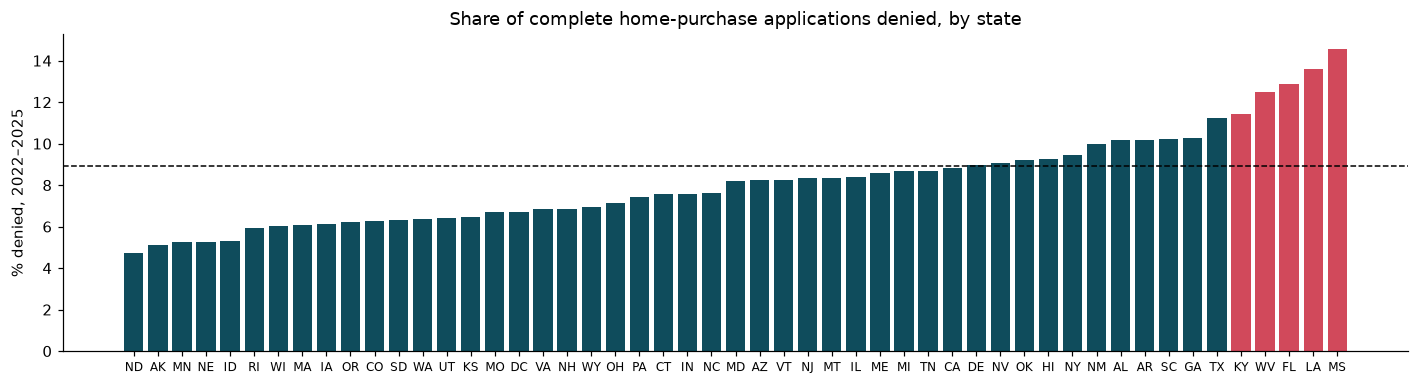

,applications,denied,median_price_k
state,,,
ND,"27,775",4.7%,$295k
AK,"26,709",5.1%,$385k
MN,"236,365",5.2%,$345k
FL,"1,117,936",12.9%,$385k
LA,"152,037",13.6%,$245k
MS,"99,880",14.5%,$235k


In [4]:
st = d.groupby("state", observed=True).agg(applications=("denied", "size"), denied=("denied", "mean"),
                                           median_price_k=("price_k", "median")).sort_values("denied")
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar(st.index.astype(str), 100 * st.denied, color=["#d1495b" if s in st.index[-5:] else "#0f4c5c" for s in st.index])
ax.axhline(100 * d.denied.mean(), color="k", ls="--", lw=1); ax.set_ylabel("% denied, 2022–2025")
ax.set_title("Share of complete home-purchase applications denied, by state"); ax.tick_params(axis="x", labelsize=8)
fig.tight_layout(); plt.show()
FACTS.update(st_lo=str(st.index[0]), st_lo_v=pct(st.denied.iloc[0]), st_hi=str(st.index[-1]), st_hi_v=pct(st.denied.iloc[-1]),
             st_big=", ".join(map(str, st.sort_values("applications").index[-3:][::-1])),
             st_price_lo=f"${st.median_price_k.min():,.0f}k", st_price_hi=f"${st.median_price_k.max():,.0f}k")
pd.concat([st.head(3), st.tail(3)]).style.format({"applications": "{:,}", "denied": "{:.1%}", "median_price_k": "${:,.0f}k"})

**What this shows.** Denial rates range from 4.7% (ND) to 14.5% (MS), and the typical home price from $225k to
$725k. The biggest markets are TX, FL, CA. So the website asks for the state: it sets the default property tax
and insurance (which change the monthly payment, and so the debt-to-income) and which lenders people there actually
use. Whether the *model* itself should see the state is a fairness question — section 7b tests it.

## 2. A fair split by time
Applications are **never shuffled across years**: the model learns from the past and is tested on the next year, the
way it would really be used.

| Set | Years | Used for |
|---|---|---|
| Train | 2022–2023 | fitting the trees |
| Validation | 2024 | choosing when to stop adding trees, and calibrating the percentages |
| **Test** | **2025** | **the final score, computed once** |

In [5]:
P = pd.read_parquet("data/predictions.parquet")
te = P[P["year"] == 2025].reset_index(drop=True)
y = te["denied"].to_numpy()
n = EV["n"]
FACTS.update(n_train=big(n["train"]), n_valid=big(n["valid"]), n_test=big(n["test"]), base=pct(y.mean()),
             all_approve=pct(1 - y.mean(), 0), n_trees=f"{EV['best_iteration']:,}", n_lenders=str(n["lenders_named"]))
print(f"train {n['train']:,} · validation {n['valid']:,} · test {n['test']:,} applications")
print(f"2025 denial rate {y.mean():.1%} → 'approve everyone' would be {1 - y.mean():.1%} accurate")
print(f"the risk model stopped at {EV['best_iteration']:,} trees (chosen on 2024)")

train 6,820,915 · validation 3,012,448 · test 3,017,153 applications
2025 denial rate 8.8% → 'approve everyone' would be 91.2% accurate
the risk model stopped at 1,231 trees (chosen on 2024)


**What this shows.** 6.8 million applications to learn from, 3.0 million to tune and 3.0 million for the final test. Only 8.8% of the 2025
applications were denied, so "approve everyone" would already be 91% accurate and completely useless.
That is why we score with PR-AUC (how well the model finds the denials) instead of accuracy.

## 3. Is it better than the rules people already use?
Three ways to rank the 2025 applications from "surely approved" to "likely denied":
* **Debt-to-income alone** — the number behind the 43% rule of thumb;
* **Logistic regression** on the same inputs as FairKey (with flexible curves for the numbers);
* **FairKey** (LightGBM, 1,231 trees, monotone in DTI and LTV).

The intervals come from 200 bootstrap re-draws of the test year (the website uses 1,000).

In [6]:
scores = {"FairKey (LightGBM)": te["p"].to_numpy(), "Logistic regression": te["p_logistic"].to_numpy(),
          "Debt-to-income alone": te["dti"].to_numpy().astype(float)}
boot = T.bootstrap(scores, y, n=200)
rows = []
for k, s in scores.items():
    lo, hi = np.percentile(boot[k], [2.5, 97.5])
    rows.append({"method": k, "PR-AUC": T.ap_fast(s, y), "95% interval": f"{lo:.3f}–{hi:.3f}"})
diff = boot["FairKey (LightGBM)"] - boot["Logistic regression"]
ap = {r["method"]: r["PR-AUC"] for r in rows}
FACTS.update(ap_fk=f"{ap['FairKey (LightGBM)']:.3f}", ap_lr=f"{ap['Logistic regression']:.3f}",
             ap_dti=f"{ap['Debt-to-income alone']:.3f}", gain=f"{diff.mean():+.3f}",
             gain_lo=f"{np.percentile(diff, 2.5):+.3f}", gain_hi=f"{np.percentile(diff, 97.5):+.3f}",
             gain_sig=("it does not include zero, so the gain is not luck: the trees capture something the classic model misses"
                       if np.percentile(diff, 2.5) > 0 else "it includes zero, so the gain could be luck"))
print(f"{len(te):,} applications in 2025 · FairKey − logistic = {diff.mean():+.3f} "
      f"[{np.percentile(diff, 2.5):+.3f}, {np.percentile(diff, 97.5):+.3f}]")
pd.DataFrame(rows).style.format({"PR-AUC": "{:.3f}"}).hide(axis="index")

3,017,153 applications in 2025 · FairKey − logistic = +0.066 [+0.065, +0.067]


method,PR-AUC,95% interval
FairKey (LightGBM),0.569,0.567–0.571
Logistic regression,0.503,0.501–0.505
Debt-to-income alone,0.327,0.326–0.329


**What this shows.** FairKey scores **0.569**, the logistic regression 0.503 and debt-to-income alone 0.327 (a coin would score 8.8%).
The gain over the logistic regression is +0.066 with a 95% interval of +0.065 to +0.067: it does not include zero, so the gain is not luck: the trees capture something the classic model misses.

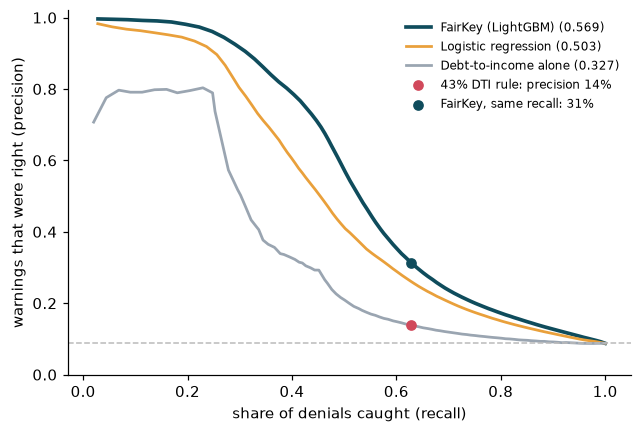

per 1,000 applications, both catching 63% of denials: the rule wrongly warns 343 approved families, FairKey 121


In [7]:
fig, ax = plt.subplots(figsize=(6.6, 4.3))
for (k, s), c in zip(scores.items(), ["#0f4c5c", "#e9a03b", "#9aa5b1"]):
    pts = np.array(T.pr_points(s, y, n=120))
    ax.plot(pts[:, 0], pts[:, 1], color=c, lw=2.4 if "Fair" in k else 1.8, label=f"{k} ({T.ap_fast(s, y):.3f})")
rule = T.rule_flag(te)
r_prec, r_rec = y[rule == 1].mean(), rule[y == 1].mean()
fk = T.at_recall(scores["FairKey (LightGBM)"], y, r_rec)
ax.scatter([r_rec], [r_prec], color="#d1495b", zorder=5, label=f"43% DTI rule: precision {r_prec:.0%}")
ax.scatter([fk["recall"]], [fk["precision"]], color="#0f4c5c", zorder=5, label=f"FairKey, same recall: {fk['precision']:.0%}")
ax.axhline(y.mean(), color="#bbb", ls="--", lw=1)
ax.set(xlabel="share of denials caught (recall)", ylabel="warnings that were right (precision)", ylim=(0, 1.02))
ax.legend(frameon=False, fontsize=8); plt.show()
rule_false = 1000 * ((rule == 1) & (y == 0)).sum() / len(y)
fk_false = 1000 * ((scores["FairKey (LightGBM)"] >= fk["threshold"]) & (y == 0)).sum() / len(y)
FACTS.update(rule_rec=pct(r_rec, 0), rule_prec=pct(r_prec, 0), fk_prec=pct(fk["precision"], 0),
             rule_false=f"{rule_false:.0f}", fk_false=f"{fk_false:.0f}")
print(f"per 1,000 applications, both catching {r_rec:.0%} of denials: the rule wrongly warns {rule_false:.0f} "
      f"approved families, FairKey {fk_false:.0f}")

**What this shows.** The red dot is the 43% rule: it catches 63% of the denials, but only 14% of its warnings are right.
Asked to catch the same 63%, FairKey's warnings are right 31% of the time. Per 1,000 applications, that is
**343 approved families wrongly warned by the rule versus 121 by FairKey** — fewer families scared off
for nothing.

## 4. Can you believe the percentages?
A risk is only useful to a person if "30%" means about 30 in 100. The trees' raw score is turned into a percentage with
Platt scaling fitted on 2024 (never on the test year). Each dot below groups 2025 applications with similar predictions.

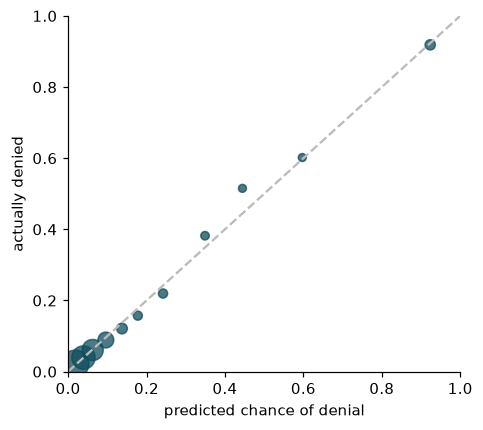

average gap between prediction and reality: 0.5 points · Brier 0.0529 (logistic 0.0582, same % for everyone 0.0800)


year,2024,2025
band,,
low,3.7%,3.7%
medium,11.1%,11.0%
high,66.5%,65.5%


In [8]:
cal = pd.DataFrame(T.calibration_bins(te["p"].to_numpy(), y))
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], ls="--", color="#bbb")
ax.scatter(cal["pred"], cal["actual"], s=20 + 300 * cal["n"] / cal["n"].max(), color="#0f4c5c", alpha=.75)
ax.set(xlabel="predicted chance of denial", ylabel="actually denied", xlim=(0, 1), ylim=(0, 1)); plt.show()
cal_err = (cal.n * (cal.pred - cal.actual).abs()).sum() / cal.n.sum()
worst = cal.loc[(cal.pred - cal.actual).abs().idxmax()]
bands = pd.DataFrame(EV["bands_check"]).pivot(index="band", columns="year", values="denied").loc[["low", "medium", "high"]]
share = pd.DataFrame(EV["bands_check"]).query("year == '2025'").set_index("band").share
FACTS.update(cal_err=f"{100 * cal_err:.1f}", brier=f"{EV['metrics']['fairkey']['brier']:.4f}",
             brier_lr=f"{EV['metrics']['logistic']['brier']:.4f}", brier_c=f"{EV['metrics']['brier_constant']:.4f}",
             low_den=pct(bands.loc["low", "2025"]), mid_den=pct(bands.loc["medium", "2025"]),
             high_den=pct(bands.loc["high", "2025"]), low_share=pct(share["low"], 0), high_share=pct(share["high"], 0),
             w_lo=pct(worst.lo, 0), w_hi=pct(worst.hi, 0), w_pred=pct(worst.pred), w_act=pct(worst.actual),
             w_n=f"{int(worst.n):,}", w_share=pct(worst.n / cal.n.sum()))
print(f"average gap between prediction and reality: {100 * cal_err:.1f} points · Brier {EV['metrics']['fairkey']['brier']:.4f} "
      f"(logistic {EV['metrics']['logistic']['brier']:.4f}, same % for everyone {EV['metrics']['brier_constant']:.4f})")
bands.style.format("{:.1%}")

**What this shows.** On average the percentage is 0.5 points away from what really happened. The biggest miss is between 40% and
50%: FairKey said 44.5% and 51.5% were really denied — a band with only 23,392 applications (0.8% of 2025).
The website's three bands hold on 2025: **"likely yes"** (78% of applications) → 3.7% denied;
**"uncertain"** → 11.0%; **"high risk"** (6%) → 65.5%. The Brier score is 0.0529
(logistic 0.0582, the same percentage for everyone 0.0800).

## 5. What drives it, and why a lender would say no
Global importance: each input's share of the trees' total gain. The monotone constraints guarantee that, all else
equal, a higher debt-to-income or loan-to-value can never *lower* the predicted risk — so the what-if advice can never
say "borrow more to be safer".

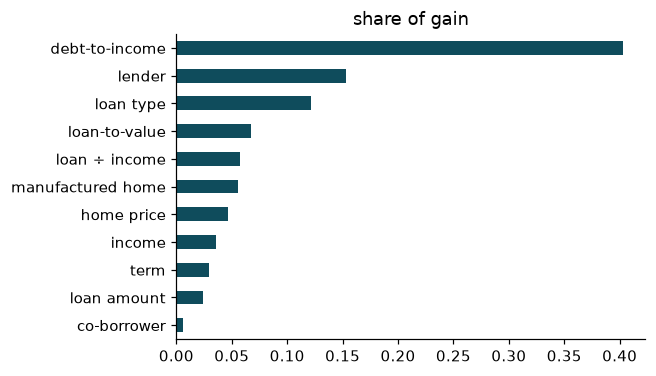

In [9]:
risk = lgb.Booster(model_file="models/risk.txt")
NICE = {"dti": "debt-to-income", "ltv": "loan-to-value", "lender": "lender", "income_k": "income", "loan_k": "loan amount",
        "price_k": "home price", "loan_to_income": "loan ÷ income", "term_years": "term", "loan_type": "loan type",
        "coapp": "co-borrower", "manufactured": "manufactured home", "state": "state"}
gain = pd.Series(risk.feature_importance("gain"), index=[NICE.get(f, f) for f in risk.feature_name()])
imp = (gain / gain.sum()).sort_values()
imp.plot.barh(figsize=(5.5, 3.6), color="#0f4c5c", title="share of gain"); plt.show()
FACTS.update(imp1=imp.index[-1], imp1_v=pct(imp.iloc[-1], 0), imp2=imp.index[-2], imp2_v=pct(imp.iloc[-2], 0),
             imp3=imp.index[-3], imp3_v=pct(imp.iloc[-3], 0))

**What this shows.** The three biggest drivers are **debt-to-income** (40% of the gain), **lender** (15%) and **loan type** (12%).
For a single application the website goes further: exact TreeSHAP shows how much *each* answer moved *that* prediction.

In [10]:
r = EV["reasons"]
rec = pd.Series(r["per_reason_recall"]).rename("found when it was the real reason")
pri = pd.Series(r["prior"]).rename("share of denials")
FACTS.update(r_top1=pct(r["top1"], 0), r_top2=pct(r["top2"], 0), r_maj=pct(r["majority"], 0), r_n=f"{r['n_test']:,}",
             r_dti=pct(r["prior"]["dti"], 0), r_credit=pct(r["prior"]["credit"], 0))
print(f"reason model (6 reasons) on {r['n_test']:,} denied 2025 applications: right first guess {r['top1']:.1%}, "
      f"right in its top two {r['top2']:.1%} · always guessing the most common reason: {r['majority']:.1%}")
pd.concat([pri, rec], axis=1).style.format("{:.0%}")

reason model (6 reasons) on 264,695 denied 2025 applications: right first guess 57.5%, right in its top two 73.6% · always guessing the most common reason: 37.4%


,share of denials,found when it was the real reason
dti,37%,90%
credit,16%,53%
collateral,15%,55%
cash,6%,9%
paperwork,15%,36%
other,11%,8%


**What this shows.** When a lender says no it must give a reason. A second model (223 trees) predicts which one: its first guess is
right **58%** of the time on 264,695 denied 2025 applications (always guessing the most common reason: 37%), and the
real reason is in its top two 74% of the time. Debt-to-income explains 37% of denials and credit history 16% —
the second one is a reason FairKey can name but not see (section 6).

## 6. Where does it fail?
The worst mistake for a family is a **missed denial**: FairKey said "likely yes" (under 8%) and the lender said no.
What did lenders say in those cases, compared with the denials FairKey did flag as "high risk"?

In [11]:
lo_cut, hi_cut = META["bands"]["low"], META["bands"]["high"]
den = te[te.denied.eq(1)]
missed, flagged = den[den.p < lo_cut], den[den.p >= hi_cut]
why = pd.DataFrame({"missed (FairKey said likely yes)": missed.reason.value_counts(normalize=True),
                    "caught (FairKey said high risk)": flagged.reason.value_counts(normalize=True)}).fillna(0)
why = why.loc[why.sum(axis=1).sort_values(ascending=False).index]
FACTS.update(low_cut=pct(lo_cut, 0), n_missed=f"{len(missed):,}", miss_share=pct(len(missed) / len(den), 0),
             miss_credit=pct(why.iloc[:, 0].get("credit", 0), 0), flag_credit=pct(why.iloc[:, 1].get("credit", 0), 0),
             miss_dti=pct(why.iloc[:, 0].get("dti", 0), 0), flag_dti=pct(why.iloc[:, 1].get("dti", 0), 0))
print(f"{len(missed):,} of {len(den):,} denials in 2025 ({len(missed) / len(den):.0%}) had been rated 'likely yes'")
why.style.format("{:.0%}")

87,186 of 264,695 denials in 2025 (33%) had been rated 'likely yes'


,missed (FairKey said likely yes),caught (FairKey said high risk)
reason,,
dti,10%,62%
credit,19%,19%
collateral,23%,7%
paperwork,22%,4%
other,16%,6%
cash,11%,2%


**What this shows.** 87,186 denials (33% of all 2025 denials) were rated "likely yes". Lenders gave **credit history** as the
reason for 19% of those misses, against 19% of the denials FairKey caught; debt-to-income was the reason
for only 10% of the misses (against 62%). In plain words: FairKey misses the families whose finances look
fine on paper but whose credit report doesn't — and credit scores are not in the public data. This is its biggest limit,
and the website says so next to every result.

In [12]:
cols = ["state", "income_k", "price_k", "ltv", "dti", "loan_type", "coapp", "p", "reason"]
ex = missed.sort_values("p").head(400).sample(6, random_state=3)[cols].copy()
ex["loan_type"] = ex.loan_type.map(F.LOAN_TYPES)
FACTS["ex_reasons"] = ", ".join(f"{k} ×{v}" for k, v in ex.reason.value_counts().items())
ex.style.format({"income_k": "${:,.0f}k", "price_k": "${:,.0f}k", "ltv": "{:.0f}%", "dti": "{:.0f}%", "p": "{:.1%}"}).hide(axis="index")

state,income_k,price_k,ltv,dti,loan_type,coapp,p,reason
TN,$83k,$795k,36%,49%,VA,1,0.5%,cash
FL,$178k,$675k,100%,33%,VA,1,0.3%,credit
VA,$96k,$515k,100%,42%,VA,0,0.5%,credit
FL,$138k,$595k,90%,43%,VA,1,0.4%,other
SC,$90k,$485k,94%,48%,VA,0,0.4%,paperwork
CO,$87k,$605k,57%,37%,Conventional,0,0.4%,dti


**What this shows.** Six real 2025 applications picked at random from the most confident misses (the lowest predicted risks that were still
denied). On paper they look safe — that is exactly why FairKey rated them low. The reasons their lenders gave: credit ×2, cash ×1, other ×1, paperwork ×1, dti ×1.
Credit history, paperwork and "other" reasons are not visible in the application numbers at all, which is why the
website shows the lender's likely reason next to the risk and says plainly that credit history is missing.

### 6b. Does it work in every state?

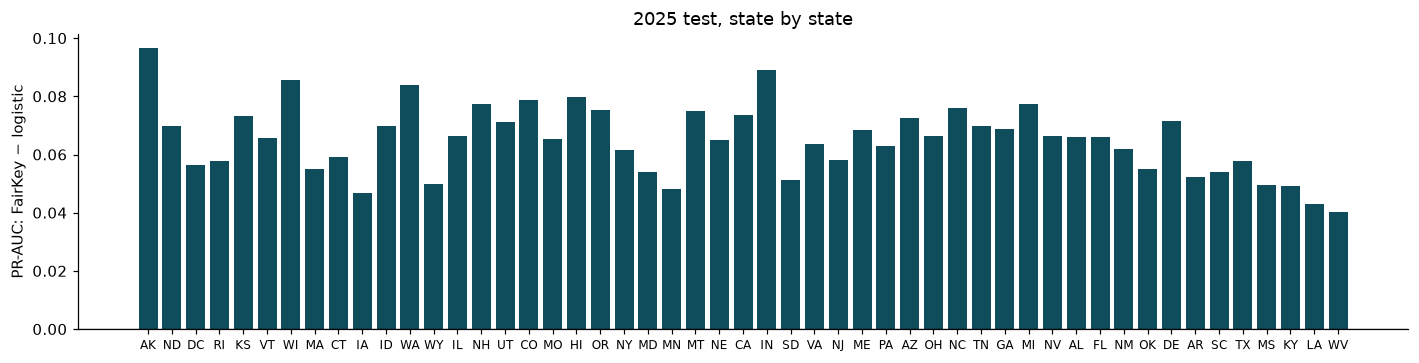

,applications,denied,FairKey,logistic,gain
state,,,,,
TX,"324,643",11.7%,0.659,0.601,+0.058
FL,"255,984",12.7%,0.617,0.551,+0.066
CA,"221,727",8.7%,0.509,0.435,+0.074
NC,"126,913",7.6%,0.555,0.479,+0.076
GA,"112,968",10.0%,0.567,0.498,+0.069
OH,"112,013",6.9%,0.543,0.477,+0.066
IL,"104,048",8.5%,0.480,0.413,+0.066
PA,"99,706",6.7%,0.523,0.460,+0.063


In [13]:
rows = []
for s_, g in te.groupby("state", observed=True):
    yy = g.denied.to_numpy()
    if yy.sum() < 30:
        continue
    rows.append({"state": str(s_), "applications": len(g), "denied": yy.mean(), "FairKey": T.ap_fast(g.p.to_numpy(), yy),
                 "logistic": T.ap_fast(g.p_logistic.to_numpy(), yy)})
per = pd.DataFrame(rows).set_index("state").sort_values("FairKey")
per["gain"] = per.FairKey - per.logistic
fig, ax = plt.subplots(figsize=(13, 3.4))
ax.bar(per.index, per.gain, color=np.where(per.gain > 0, "#0f4c5c", "#d1495b"))
ax.axhline(0, color="k", lw=.8); ax.set_ylabel("PR-AUC: FairKey − logistic"); ax.tick_params(axis="x", labelsize=8)
ax.set_title("2025 test, state by state"); fig.tight_layout(); plt.show()
FACTS.update(n_per=str(len(per)), n_win=str(int((per.gain > 0).sum())), per_lo=per.index[0], per_lo_v=f"{per.FairKey.iloc[0]:.3f}",
             per_hi=per.index[-1], per_hi_v=f"{per.FairKey.iloc[-1]:.3f}", gain_med=f"{per.gain.median():+.3f}")
per.sort_values("applications", ascending=False).head(8).style.format(
    {"applications": "{:,}", "denied": "{:.1%}", "FairKey": "{:.3f}", "logistic": "{:.3f}", "gain": "{:+.3f}"})

**What this shows.** FairKey beats the logistic regression in **51 of 51** states and DC (median gain +0.066 PR-AUC).
Its score ranges from 0.372 (AK) to 0.726 (WV): PR-AUC depends on how many denials a state has, so
the fair comparison is against the logistic regression in the same state, which is what the bars show.

## 7. The fairness audit
FairKey is blind to race, ethnicity, sex and age — those columns are used **only** here. But blind is not the same as
fair: other inputs can stand in for them. For every group we compare how often its 2025 applications were **actually
denied** with what FairKey **expected** from their finances. A ratio above 1 means lenders denied that group more often
than its finances explain. We also count how often FairKey wrongly flagged *approved* families in each group.

In [14]:
def table(k):
    t = pd.DataFrame(FAIR[k])
    t["ratio (95% interval)"] = t.apply(lambda r: f"×{r['ratio']:.2f} ({r['ratio_ci'][0]:.2f}–{r['ratio_ci'][1]:.2f})", axis=1)
    return t[["group", "n", "observed", "expected", "ratio (95% interval)", "false_flag", "caught"]].style.format(
        {"n": "{:,}", "observed": "{:.1%}", "expected": "{:.1%}", "false_flag": "{:.1%}", "caught": "{:.0%}"}).hide(axis="index")
R = {r["group"]: r for r in FAIR["race"]}
FACTS.update(b_obs=pct(R["Black"]["observed"]), b_exp=pct(R["Black"]["expected"]), w_obs=pct(R["White"]["observed"]),
             w_exp=pct(R["White"]["expected"]), bw=f"{R['Black']['ratio'] / R['White']['ratio']:.2f}",
             h_ratio=f"{R['Hispanic']['ratio']:.2f}", b_ratio=f"{R['Black']['ratio']:.2f}", w_ratio=f"{R['White']['ratio']:.2f}",
             b_ff=pct(R["Black"]["false_flag"]), w_ff=pct(R["White"]["false_flag"]), h_ff=pct(R["Hispanic"]["false_flag"]))
table("race")

group,n,observed,expected,ratio (95% interval),false_flag,caught
White,"1,596,980",6.4%,7.4%,×0.86 (0.85–0.86),2.2%,45%
Black,"229,912",17.3%,13.9%,×1.24 (1.23–1.25),4.0%,48%
Hispanic,"417,443",12.8%,11.6%,×1.11 (1.10–1.11),2.8%,49%
Asian,"200,697",8.5%,8.0%,×1.07 (1.05–1.08),1.4%,48%
Other or two+,"235,232",8.8%,8.8%,×1.00 (0.99–1.01),2.7%,53%
Not provided,"336,889",9.4%,8.6%,×1.09 (1.08–1.10),2.3%,44%


**What this shows.** Black applicants were denied 17.3% of the time; from their finances FairKey expected 13.9% (ratio ×1.24).
White applicants: 6.4% against 7.4% expected (×0.86). **With the same finances, Black applicants were denied
×1.45 as often as White applicants.** Part of that gap could be credit history, which the public data does not include —
we can't rule that out and we say so. The model's own errors are uneven too: it wrongly flags 4.0% of approved Black
families, 2.8% of Hispanic and 2.2% of White ones, because it predicts higher risk where denials are more common.

In [15]:
SX = {r["group"]: r["ratio"] for r in FAIR["sex"]}
AG = [r["ratio"] for r in FAIR["age"] if r["group"] != "Not provided"]
sx = [v for k, v in SX.items() if k != "Not provided"]
FACTS.update(sex_lo=f"{min(sx):.2f}", sex_hi=f"{max(sx):.2f}", age_lo=f"{min(AG):.2f}", age_hi=f"{max(AG):.2f}",
             np_sex=f"{SX.get('Not provided', float('nan')):.2f}", np_race=f"{R['Not provided']['ratio']:.2f}")
display(table("sex")); display(table("age"))

group,n,observed,expected,ratio (95% interval),false_flag,caught
Male,"1,009,014",9.4%,9.4%,×1.00 (0.99–1.00),2.6%,45%
Female,"668,480",10.8%,10.6%,×1.01 (1.01–1.02),2.8%,50%
Joint,"1,197,291",6.9%,7.2%,×0.96 (0.96–0.97),2.0%,48%
Not provided,"142,368",10.5%,9.0%,×1.17 (1.15–1.18),2.5%,43%


group,n,observed,expected,ratio (95% interval),false_flag,caught
<25,"208,528",9.7%,10.3%,×0.93 (0.92–0.94),2.8%,52%
25-34,"978,051",7.4%,8.0%,×0.92 (0.92–0.93),2.0%,46%
35-44,"800,384",8.9%,8.6%,×1.03 (1.02–1.03),2.2%,46%
45-54,"478,314",10.2%,9.5%,×1.08 (1.07–1.08),2.6%,47%
55-64,"326,867",10.0%,9.4%,×1.07 (1.06–1.08),2.9%,48%
65-74,"170,106",8.7%,8.9%,×0.98 (0.97–0.99),3.2%,51%
>74,"54,842",8.6%,9.1%,×0.94 (0.92–0.97),4.1%,53%


**What this shows.** By sex and age the ratios stay much closer to 1 than by race: from ×0.96 to ×1.01 by sex, and from ×0.92 to
×1.08 by age. Applicants who did not report their sex or race are kept as their own group: they are denied more often
than their finances explain (×1.17 and ×1.09). The public data does not tell us why.

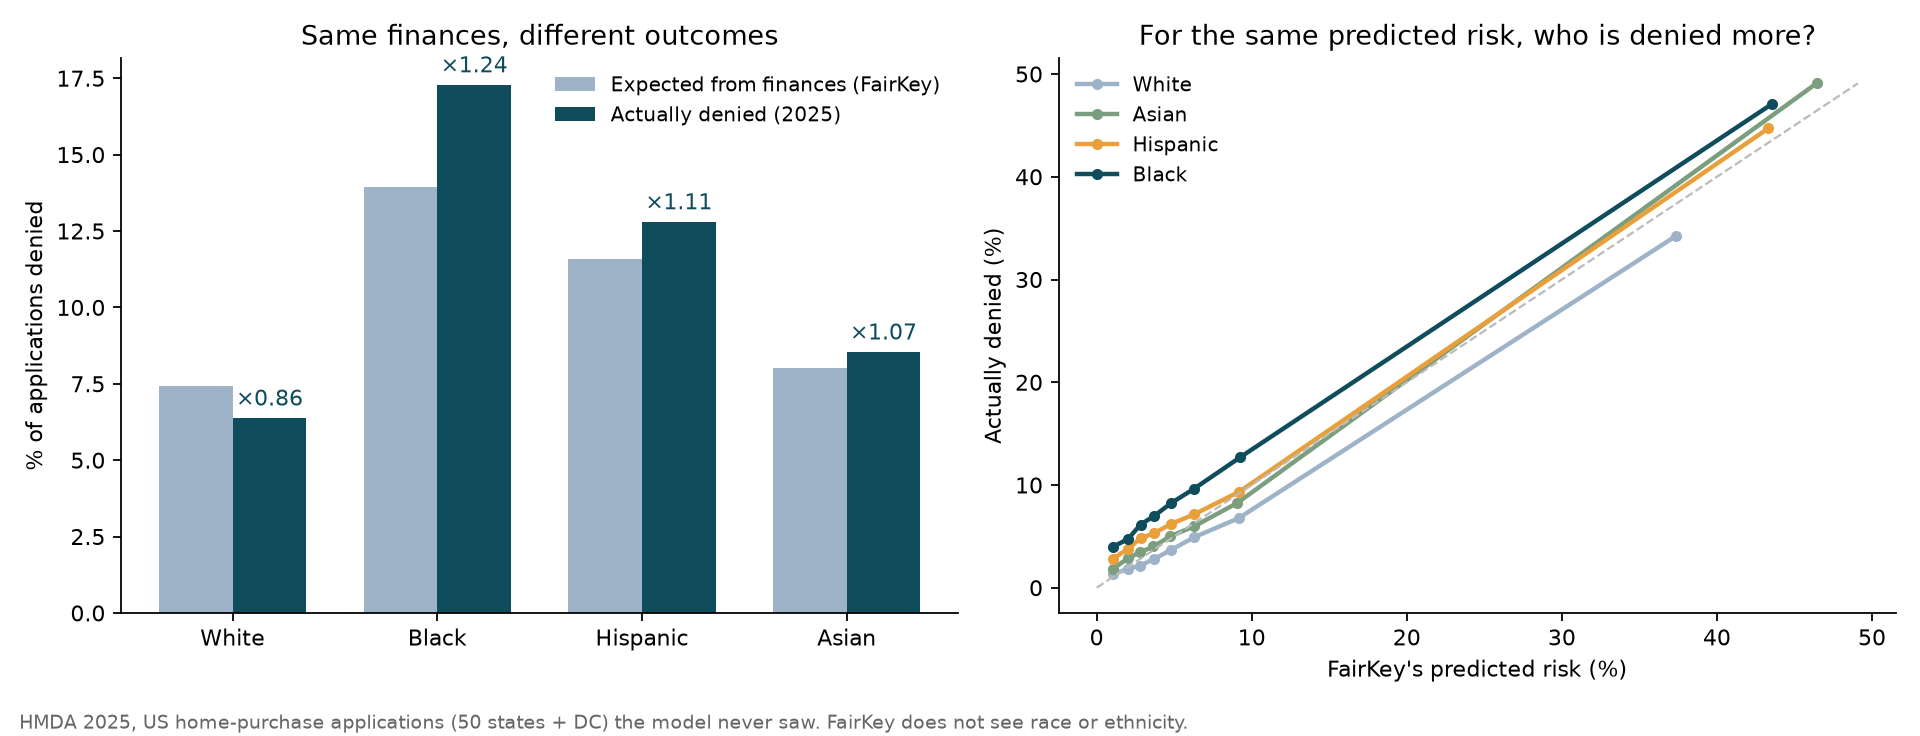

In [16]:
from IPython.display import Image
CR = FAIR["calibration_race"]
above = lambda g: sum(a["actual"] > b["actual"] for a, b in zip(CR[g], CR["White"]))
FACTS.update(cal_b=str(above("Black")), cal_h=str(above("Hispanic")), cal_k=str(min(len(CR["Black"]), len(CR["White"]))))
Image("figures/fairness_race.png", width=860)

**What this shows.** Left: how often each group was denied, next to what FairKey expected from its finances. Right: applications grouped by
FairKey's predicted risk, and the share really denied in each group. The Black line sits above the White line at
8 of 8 levels of risk and the Hispanic line at 8, so the gap is not explained by a few extreme cases.
It also means FairKey is **not** calibrated for every group: for Black and Hispanic applicants, reality runs above its
number. We chose that on purpose — the same finances get the same answer — rather than let race into the model.

### 7b. Which inputs could stand in for race? The rule we used
**Rule: keep an input only if it adds accuracy without mainly encoding race.** We tested it on every place-based input.
First, a second model tries to guess whether an applicant is Black or Hispanic (vs. White) from each set of inputs
(proxy AUC). Then we trained five versions of FairKey on the same years and compared accuracy with how often each one
wrongly flagged approved families.

In [17]:
px = pd.Series({k: v["auc"] for k, v in FAIR["proxy"].items()}, name="proxy AUC")
nb = FAIR["neighbourhood"]
vers = [k for k, v in nb.items() if isinstance(v, dict) and "ap" in v]
cmp = pd.DataFrame({k: {"PR-AUC": nb[k]["ap"], **{f"wrongly flagged · {g}": nb[k]["false_flag"][g]
                                                  for g in ["Black", "Hispanic", "White"]}} for k in vers}).T
cmp = cmp.join(px)
for k in vers:
    kk = k.replace("+", "_")                                 # note keys are plain words: shipped+state → shipped_state
    FACTS[f"ap_{kk}"] = f"{nb[k]['ap']:.3f}"
    FACTS[f"px_{kk}"] = f"{px.get(k, float('nan')):.3f}"
    FACTS[f"rB_{kk}"] = f"{nb[k]['ratio']['Black']:.2f}"
    for g in ["Black", "Hispanic", "White"]:
        FACTS[f"ff_{kk}_{g}"] = pct(nb[k]["false_flag"][g])
for name, a, b in (("lender", "finances", "shipped"), ("state", "shipped", "shipped+state"),
                   ("county", "shipped", "shipped+county"), ("nbhd", "shipped+county", "neighbourhood")):
    FACTS[f"d_{name}"] = f"{nb[b]['ap'] - nb[a]['ap']:+.3f}"
cmp.style.format({"PR-AUC": "{:.3f}", "proxy AUC": "{:.3f}", **{c: "{:.1%}" for c in cmp.columns if "flag" in c}})

,PR-AUC,wrongly flagged · Black,wrongly flagged · Hispanic,wrongly flagged · White,proxy AUC
finances,0.543,3.6%,2.6%,2.1%,0.746
shipped,0.569,4.0%,2.8%,2.2%,0.757
shipped+state,0.574,4.4%,3.0%,2.1%,0.813
shipped+county,0.576,4.7%,3.2%,2.1%,0.851
neighbourhood,0.577,4.8%,3.3%,2.1%,0.870


**What this shows.** We shipped **finances + lender**. The lender passed the rule: +0.027 PR-AUC, and it barely helps guess race
(proxy AUC 0.746 → 0.757). It is not free: approved Black families wrongly flagged went from
3.6% to 4.0%, so we publish that cost. **Place failed.** The state would add only +0.005
PR-AUC, yet the proxy AUC jumps to 0.813 and wrong flags for approved Black families rise to
4.4%; the county adds +0.007, with a proxy AUC of 0.851 and 4.7%.
Across the U.S., where you live stands in for race. Place even makes the group ratios at the start of section 7 look *better* (Black ×1.24 →
×1.21 with the state, ×1.19 with the county), because the model learns to expect more
denials where minority applicants live: it copies the lenders' gap into the prediction instead of measuring it, and
wrongly flags more Black families while doing so. So on the website your state sets taxes, insurance and the lender
list, but the model never sees where you live.

In [18]:
tw = next((nb[k]["twin"] for k in vers if nb[k].get("twin")), None)
if tw:
    FACTS.update(twin=f"{tw['pts']:+.2f}", twin_share=pct(tw["share_higher"], 0))
    print(f"the same 2025 families moved from a census tract with {tw['minority_lo']:.0f}% minority residents to one with "
          f"{tw['minority_hi']:.0f}%: predicted risk {tw['risk_lo']:.2%} → {tw['risk_hi']:.2%} "
          f"({tw['pts']:+.2f} points; higher for {tw['share_higher']:.0%} of them)")

the same 2025 families moved from a census tract with 10% minority residents to one with 75%: predicted risk 8.45% → 9.59% (+1.14 points; higher for 93% of them)


**What this shows.** The **twin test** takes the same 2025 families and only changes their neighbourhood from mostly white to mostly minority.
In the neighbourhood version, their predicted risk moves by +1.14 points on average (higher for 93% of them),
with the finances unchanged. Whatever the size, that part of the prediction prices the neighbourhood, not the family,
and the version had already failed the rule above (only +0.001 PR-AUC over the county version).

### 7c. State by state: the lender gap
For each state with at least 300 Black (or Hispanic) and 300 White applicants in 2025: how many times as often were they
denied as White applicants **that FairKey rated the same**? Bars show the 95% interval (block bootstrap). The website
shows the same numbers as a map you can tap.

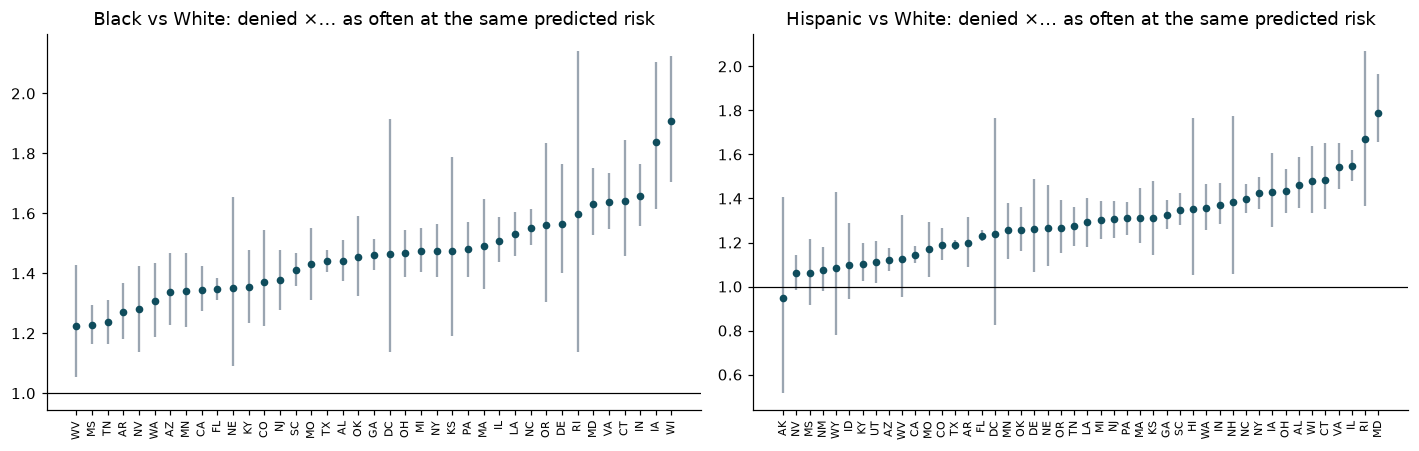

In [19]:
S = FAIR["states"]
def gap(key):
    r = pd.DataFrame({k: v[key] for k, v in S.items() if v.get(key)}).T
    r[["lo", "hi"]] = pd.DataFrame(r.ci.tolist(), index=r.index)
    return r.sort_values("ratio")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, key, name in zip(axes, ["black", "hispanic"], ["Black vs White", "Hispanic vs White"]):
    g = gap(key)
    ax.errorbar(range(len(g)), g.ratio, yerr=[g.ratio - g.lo, g.hi - g.ratio], fmt="o", ms=4, color="#0f4c5c", ecolor="#9aa5b1")
    ax.axhline(1, color="k", lw=.8); ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index, fontsize=7, rotation=90)
    ax.set_title(f"{name}: denied ×… as often at the same predicted risk")
    FACTS.update({f"{key}_m": str(len(g)), f"{key}_above": str(int((g.lo > 1).sum())), f"{key}_below": str(int((g.hi < 1).sum())),
                  f"{key}_hi": g.index[-1], f"{key}_hi_v": f"{g.ratio.iloc[-1]:.2f}", f"{key}_lo": g.index[0],
                  f"{key}_lo_v": f"{g.ratio.iloc[0]:.2f}", f"{key}_med": f"{g.ratio.median():.2f}"})
fig.tight_layout(); plt.show()

**What this shows.** Black applicants could be measured in 39 states (including DC). In **39** of them they were denied
clearly more often than White applicants with the same predicted risk (the whole interval above ×1), and in 0
clearly less often. The median state is ×1.46; the highest is WI (×1.91), the lowest WV
(×1.22). For Hispanic applicants (46 states) the median is ×1.28, clearly above ×1 in
38. The gap is not a quirk of one state: it shows up across the country, with different sizes.

## 8. The website: the same model, in your browser
The website has no server. `train.py` exports both models as arrays (`web/data/model.json`) and a small JavaScript
engine (`web/fk-model.js`) walks the trees and computes exact path-dependent TreeSHAP on the visitor's device.
`tests/check_engine.mjs` compares it with LightGBM's own predictions and SHAP values (`pred_contrib=True`) on 500 real
test applications.

In [20]:
try:
    out = subprocess.run(["node", "tests/check_engine.mjs"], capture_output=True, text=True, timeout=300)
    print(out.stdout or out.stderr)
except FileNotFoundError:
    print("node is not installed here: run `node tests/check_engine.mjs` to repeat the check")

500 applications · max |raw| 2.40e-6 · max |SHAP| 1.65e-6 · max |base| 1.16e-7 · max |reason p| 3.57e-7 · SHAP sums 4.04e-14 · PASS
all lenders at once (Florida weights) · rawCats 0.00e+0 · leavesCats 0.00e+0 · mix SHAP sums 1.69e-14 · vs brute-force Shapley 7.58e-15 · PASS



In [21]:
out = subprocess.run([sys.executable, "tests/check_guards.py"], capture_output=True, text=True, timeout=600)
print(out.stdout or out.stderr)

PASS  risk model: only pre-application inputs · 11 inputs: income_k, loan_k, price_k, ltv, dti, loan_to_income, term_years, coapp, manufactured, loan_type, lender
PASS  reason model: only pre-application inputs · 11 inputs: income_k, loan_k, price_k, ltv, dti, loan_to_income, term_years, coapp, manufactured, loan_type, lender
PASS  browser model: only pre-application inputs · 11 inputs: income_k, loan_k, price_k, ltv, dti, loan_to_income, term_years, coapp, manufactured, loan_type, lender
PASS  browser risk model has the same trees as LightGBM · 1231 vs 1231
PASS  browser reasons model has the same trees as LightGBM · 1338 vs 1338
PASS  risk never goes down when dti goes up · 2,000 real 2025 applications × 61 values · largest step down 0.0e+00
PASS  risk never goes down when ltv goes up · 2,000 real 2025 applications × 41 values · largest step down 0.0e+00
PASS  train < validation < test, by year · [2022, 2023] → [2024] → [2025]
PASS  bands keep their order and hold from 2024 to 2025 ·

**What this shows.** The browser engine gives the same probabilities and the same explanations as LightGBM (differences around one in a
million, from rounding). The second line checks the shortcut used when no lender is chosen: the page needs the
average over every lender in your state, so it walks each tree once for all 50 lenders together and computes the exact
SHAP values of that average. It is checked against one lender at a time and against brute-force Shapley values (every
one of the 1,024 coalitions of the other inputs). On top of the model, the page adds: a state picker (local taxes, insurance and lenders), six
example families, a "tell it in your own words" box (simple word rules, not AI), a what-if search that tries realistic
changes and ranks them, a risk map by price and down payment, a comparison of the lenders active in your state, a
"reality check" with the most similar real 2025 applications, a tree-by-tree view of the AI deciding, and this audit.
Nothing typed on the page is sent anywhere.

The last output (`tests/check_guards.py`) reads the files the website actually loads and tests the project's promises: no input that reveals
race, sex or age or is only known after the decision; the same trees in the browser as in LightGBM; risk that never
goes down when debt-to-income or loan-to-value goes up; years that never overlap; bands that hold from 2024 to 2025;
and a public sample with no identifiers.

## 9. Limitations and next steps
* **No credit scores** in public data: section 6 shows this is where FairKey fails most. Strong credit → the real risk is
  lower than shown; weak credit → higher. Next step: let users add a self-reported credit band, trained on a public
  dataset that includes scores (for example Fannie Mae / Freddie Mac loan-level data, for approved loans only).
* **Lenders serve different customers.** The lender comparison is a lead for shopping around, not a ranking of who is fair,
  and not proof that switching lender would change the answer.
* **Observational data:** "what would change it" is the model's estimate, not a promise.
* **Home purchases only**, first mortgages on homes people will live in, 2022–2025; markets and rules change, so the model
  should be retrained every year when the new HMDA file comes out.
* **Small states:** where a state has fewer than 300 Black (or Hispanic) and 300 White applicants in 2025, the gap is not
  measured — the map on the website greys it out instead of guessing.
* **The fairness gaps describe lenders' past decisions.** The audit measures them; it can't remove them, and part of them
  could be credit history we can't see.

> This project is a prototype and is not financial advice.